In [1]:
from astropy.io import fits
from pathlib import Path
import numpy as np
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
#import pathlib as Path
#here = Path(".")

##Paths to each folder
ubai2505m = Path("hst-data/Calibration/ubai2505m")
ubai2507m = Path("hst-data/Calibration/ubai2507m")
ubai2508m = Path("hst-data/Calibration/ubai2508m")

#raw = ubai2505m/"ubai2505m_.fits"
#Obtain the files from each folder 
def obtain_files(name): #Name of the file you want to obtain, Folder from where you want to obtain file
    library= {
        "raw" : ubai2505m/"ubai2505m_raw.fits",
        "bias" : ubai2505m/"ubai2505m_biasfile.fits",
        "blev" : ubai2505m/"ubai2505m_blevfile.fits",
        "dark" : ubai2505m/"ubai2505m_darkfile.fits",
        "flat" : ubai2505m/"ubai2505m_flatfile.fits",
        "mask" : ubai2505m/"ubai2505m_maskfile.fits",
    }
    data = library[name]
    return data

def exp_time(file_raw):
    with fits.open(file_raw) as hdul:
        data_raw = hdul[1].data
        exp_time = hdul[0].header.get('EXPTIME',0.0)
    return exp_time, data_raw


def masking(file_mask, blevcorr):
    with fits.open(file_mask) as hdul:
        #header_mask= hdul[0].header
        data_mask = hdul[0].data
        #info = hdul.info()
    
        condition = (data_mask == 0) | (data_mask == 256)
        masked_raw = np.where(condition, blevcorr, np.nan)
    return masked_raw,data_mask


#Apply blev data
def corrected_raw_data_blev(file_blev, file_raw):
    with fits.open(file_blev) as hdul:
        overscan_region = hdul[1].data[9:790, 8:14]
        odd = overscan_region[:, 0::2]
        even = overscan_region[:, 1::2]
        mean_odd = np.mean(odd)
        mean_even =  np.mean(even)
    with fits.open(file_raw) as hdul:
        raw_data = hdul[1].data
        corrected_raw_data = raw_data.copy()
        corrected_raw_data[:, 0::2] = raw_data[:, 0::2] - mean_odd
        corrected_raw_data[:, 1::2] = raw_data[:, 1::2] - mean_even
    
    return corrected_raw_data
    

#apply bias
def apply_bias(file_bias, corrected_raw_data):
    with fits.open(file_bias) as hdul:
        bias = hdul[0].data
        bias_correct = corrected_raw_data-bias
        bias_correct
    return bias_correct

#apply dark
def apply_dark(file_dark, bias_correct, exp_time):
    with fits.open(file_dark) as hdul:
        dark = hdul[0].data
        dark_correct = bias_correct-(dark*exp_time)
        dark_correct
    return dark_correct

def apply_flat(file_flat, dark_correct):
    with fits.open(file_flat) as hdul:
        flat = hdul[0].data
        flat_correct = dark_correct*flat
    return flat_correct

def calculate_mean_and_stndev(flat_correct): # It's okay (Check)
    #sum = 0
    #sum2 = 0
    #for i in flat_correct:
        
    #    n = len(flat_correct)
    #    sum +=i
        
    #mean = sum/n
    #for i in flat_correct:
    #    sum2 += (i - mean)**2
    #standev = ((1/(n-1))*(sum2))**0.5
    #condition = ((mean-3*standev)> flat_correct) & (flat_correct>(mean+3*standev))
    #sky = np.median(condition)
    sky_corr = flat_correct - 1
    return sky_corr


In [8]:
raw_data = obtain_files("raw")
blev_data = obtain_files("blev")
bias_data = obtain_files("bias")
dark_data = obtain_files("dark")
flat_data = obtain_files("flat")
mask_data = obtain_files("mask")

time, data = exp_time(raw_data)



blev_corr = corrected_raw_data_blev(blev_data,raw_data)
#blev_corr_mask = corrected_raw_data_mask(blev_data,masking)

masking, maskdata = masking(mask_data,blev_corr)

bias_correct = apply_bias(bias_data, blev_corr)

dark_correct = apply_dark(dark_data, bias_correct, time)

flat_correct = apply_flat(flat_data, dark_correct)

sky_correct = calculate_mean_and_stndev(flat_correct)

#hdul[0].header.get('EXPTIME',0.0)
#obtain_files("raw")
#with fits.open(library[name]) as hdul:
     #   data = hdul[0].data

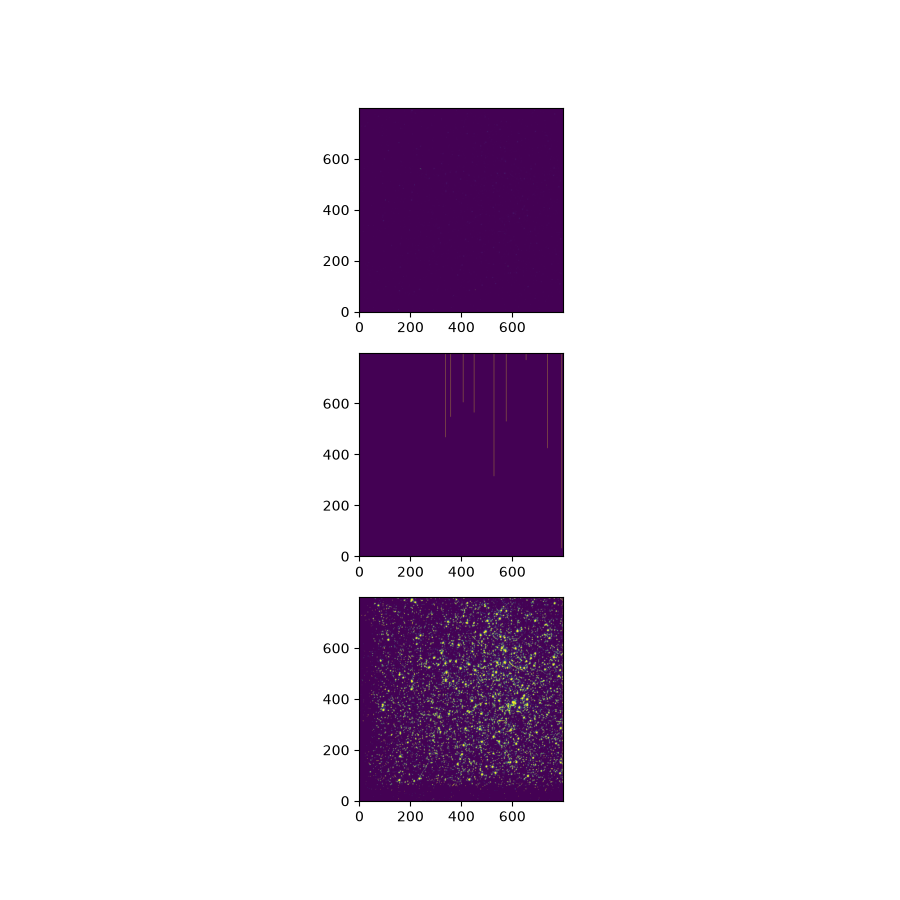

In [9]:
%matplotlib widget
plt.close('all')

# we'll use the pc chip
pc_data = data[0].copy()
pc_data1 = maskdata[0].copy()
pc_data2 = sky_correct[0].copy()

vmin = pc_data.min()
vmax = pc_data.max()
vmin1 = pc_data1.min()
vmax1 = pc_data1.max()


fig, (ax, ax1, ax2) = plt.subplots(3,1, figsize=(9, 9))


ax.imshow(pc_data, origin='lower', vmin=vmin, vmax=vmax)
ax1.imshow(pc_data1, origin='lower', vmin=vmin1, vmax=vmax1)
ax2.imshow(pc_data2, origin='lower', vmin=0, vmax=5)

In [3]:
def obtain_files(name): #Name of the file you want to obtain, Folder from where you want to obtain file
    library= {
        "raw" : ubai2508m/"ubai2508m_raw.fits",
        "bias" : ubai2508m/"ubai2508m_biasfile.fits",
        "blev" : ubai2508m/"ubai2508m_blevfile.fits",
        "dark" : ubai2508m/"ubai2508m_darkfile.fits",
        "flat" : ubai2508m/"ubai2508m_flatfile.fits",
        "mask" : ubai2508m/"ubai2508m_maskfile.fits",
    }
    data = library[name]
    return data

raw_data = obtain_files("raw")
blev_data = obtain_files("blev")
bias_data = obtain_files("bias")
dark_data = obtain_files("dark")
flat_data = obtain_files("flat")
mask_data = obtain_files("mask")

time1, data1 = exp_time(raw_data)



blev_corr1 = corrected_raw_data_blev(blev_data,raw_data)
#blev_corr_mask = corrected_raw_data_mask(blev_data,masking)

masking1, maskdata1 = masking(mask_data,blev_corr1)

bias_correct1 = apply_bias(bias_data, blev_corr1)

dark_correct1 = apply_dark(dark_data, bias_correct1, time1)

flat_correct1 = apply_flat(flat_data, dark_correct1)

sky_correct1 = calculate_mean_and_stndev(flat_correct1)

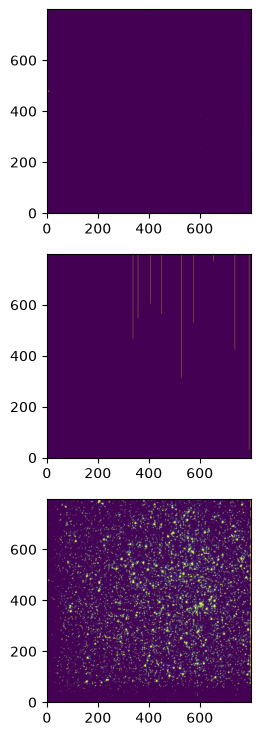

In [4]:
plt.close('all')

# we'll use the pc chip
pc_data = data1[0].copy()
pc_data1 = maskdata1[0].copy()
pc_data2 = sky_correct1[0].copy()

vmin = pc_data.min()
vmax = pc_data.max()
vmin1 = pc_data1.min()
vmax1 = pc_data1.max()


fig, (ax, ax1, ax2) = plt.subplots(3,1, figsize=(9, 9))


ax.imshow(pc_data, origin='lower', vmin=vmin, vmax=vmax)
ax1.imshow(pc_data1, origin='lower', vmin=vmin1, vmax=vmax1)
ax2.imshow(pc_data2, origin='lower', vmin=0, vmax=5)

In [7]:
def obtain_files(name): #Name of the file you want to obtain, Folder from where you want to obtain file
    library= {
        "raw" : ubai2507m/"ubai2507m_raw.fits",
        "bias" : ubai2507m/"ubai2507m_biasfile.fits",
        "blev" : ubai2507m/"ubai2507m_blevfile.fits",
        "dark" : ubai2507m/"ubai2507m_darkfile.fits",
        "flat" : ubai2507m/"ubai2507m_flatfile.fits",
        "mask" : ubai2507m/"ubai2507m_maskfile.fits",
    }
    data = library[name]
    return data

def exp_time(file_raw):
    with fits.open(file_raw) as hdul:
        data_raw = hdul[0].data
        exp_time = hdul[0].header.get('EXPTIME',0.0)
    return exp_time, data_raw
def corrected_raw_data_blev(file_blev, file_raw):
    with fits.open(file_blev) as hdul:
        overscan_region = hdul[0].data[0][9:790, 8:14]
        odd = overscan_region[:, 0::2]
        even = overscan_region[:, 1::2]
        mean_odd = np.mean(odd)
        mean_even =  np.mean(even)
    with fits.open(file_raw) as hdul:
        raw_data = hdul[0].data[0]
        corrected_raw_data = raw_data.copy()
        corrected_raw_data[:, 0::2] = raw_data[:, 0::2] - mean_odd
        corrected_raw_data[:, 1::2] = raw_data[:, 1::2] - mean_even
    
    return corrected_raw_data

def masking(file_mask, blevcorr):
    with fits.open(file_mask) as hdul:
        #header_mask= hdul[0].header
        data_mask = hdul[0].data[0]
        #info = hdul.info()
    
        condition = (data_mask == 0) | (data_mask == 256)
        masked_raw = np.where(condition, blevcorr, np.nan)
    return masked_raw,data_mask
    
raw_data = obtain_files("raw")
blev_data = obtain_files("blev")
bias_data = obtain_files("bias")
dark_data = obtain_files("dark")
flat_data = obtain_files("flat")
mask_data = obtain_files("mask")

time2, data2 = exp_time(raw_data)



blev_corr2 = corrected_raw_data_blev(blev_data,raw_data)
#blev_corr_mask = corrected_raw_data_mask(blev_data,masking)

masking2, maskdata2 = masking(mask_data,blev_corr2)

bias_correct2 = apply_bias(bias_data, blev_corr2)

dark_correct2 = apply_dark(dark_data, bias_correct2, time2)

flat_correct2 = apply_flat(flat_data, dark_correct2)

sky_correct2 = calculate_mean_and_stndev(flat_correct2)

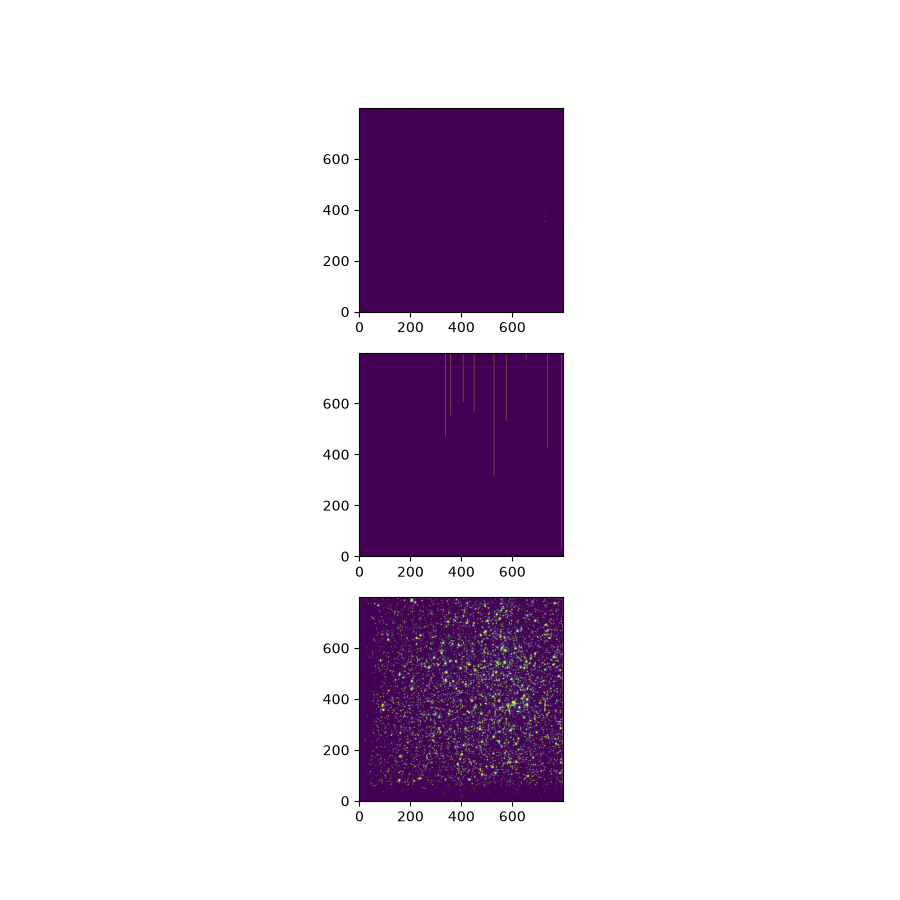

In [9]:
%matplotlib widget
plt.close('all')

# we'll use the pc chip
pc_data = data2[0].copy()
pc_data1 = maskdata2.copy()
pc_data2 = sky_correct2[0].copy()

vmin = pc_data.min()
vmax = pc_data.max()
vmin1 = pc_data1.min()
vmax1 = pc_data1.max()


fig, (ax, ax1, ax2) = plt.subplots(3,1, figsize=(9, 9))


ax.imshow(pc_data, origin='lower', vmin=vmin, vmax=vmax)
ax1.imshow(pc_data1, origin='lower', vmin=vmin1, vmax=vmax1)
ax2.imshow(pc_data2, origin='lower', vmin=0, vmax=5)